In [1]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os
import cmath 
import json

In [2]:
data = pd.read_csv("données/LucasBenjamin_5ae9cde00335e200019e9eed.csv", skiprows=1, index_col=3)
data

,rt,url,trial_type,time_elapsed,internal_node_id,success,responses,view_history,trial_rt,response_rts,stimulus,presented_angles,stimulus_rotations,key_press,final_angle,confidence,target,score,correct
trial_index,,,,,,,,,,,,,,,,,,,
0,18657.0,external-consent.html,external-html,18692,0.0-0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,fullscreen,23307,0.0-1.0,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,14396.0,NaN,survey-dropdown,37704,0.0-2.0,NaN,"{""0"":""25-40"",""1"":""F""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,69634.0,NaN,survey-text,107340,0.0-3.0,NaN,"{""Q0"":""5ae9cde00335e200019e9eed""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,80368.0,NaN,instructions,187708,0.0-4.0,NaN,NaN,"[{""page_index"":0,""viewing_time"":48649},{""page_...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,NaN,NaN,lb-SeqAns-visual,4828326,0.0-224.0,NaN,NaN,NaN,2426.0,NaN,Stims/Gabor_img/Gabor_0.png,218.4099821053,-45,NaN,-9.130176,0.0,173.409982,10.0,NaN
284,NaN,NaN,lb-SeqAns-visual,4833865,0.0-225.0,NaN,NaN,NaN,2508.0,NaN,Stims/Gabor_img/Gabor_0.png,195.9147529961,0,NaN,15.718573,0.0,15.914753,10.0,NaN
285,NaN,NaN,lb-SeqAns-visual,4844768,0.0-226.0,NaN,NaN,NaN,1822.0,NaN,Stims/Gabor_img/Gabor_0.png,"159.3437590786,153.8696178772,90.66764952,150....","-45,-45,0,0,0",NaN,-79.343152,0.0,105.643527,10.0,NaN


## Fonctions

In [3]:
def CircularMean(a):
    if len(a)==0:
        return(np.nan)
    resulting_vector = 0
    for i in range(len(a)):
        if ~np.isnan(a[i]):
            resulting_vector+= cmath.exp(complex(0, a[i]))
    return(np.angle(resulting_vector))

In [4]:
def Angle_moyen_circulaire(angle_list_deg):
    rad_doubled = 2 * angle_list_deg                         # ×2 AVANT
    mean_doubled = CircularMean(rad_doubled)                 # TA fonction (rad)
    mean_ori_rad = mean_doubled / 2                          # ÷2 APRÈS
    return mean_ori_rad % np.pi                                   

In [5]:
def circular_error_180(a, b):
    return ((a - b + np.pi/2) % np.pi) - np.pi/2   # équivalent de [-90°, +90°]

## Filtering du dataframe pour 1 sujet

### dataframe en degré

In [6]:
df_filtered = data[data["stimulus_rotations"].notna()]
df_filtered = df_filtered.drop(columns=["rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
df_filtered.reset_index(drop=True, inplace=True)
df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['score'] = df_filtered['score'].astype(int)
df_filtered["expected_angles"] = df_filtered.apply(lambda row : [x + y for x,y in zip(row["presented_angles"],row["stimulus_rotations"])], axis=1)
df_filtered["expected_targets"] = df_filtered['expected_angles'].apply(np.mean)%180 # the best they could have done with what they were given

df_filtered = df_filtered.dropna(subset=["final_angle"])

In [7]:
df_filtered

,trial_rt,presented_angles,stimulus_rotations,final_angle,target,score,expected_angles,expected_targets
0,2305.0,"[186.3297408056, 172.4988425288, 115.6656248854]","[-45.0, -45.0, 45.0]",-24.646771,143.138643,6,"[141.3297408056, 127.4988425288, 160.6656248854]",143.164736
1,1958.0,"[98.0630303799, 193.2006295208, 49.6275131924,...","[45.0, -45.0, 45.0, -45.0, 0.0, -45.0, -45.0]",-13.958290,132.662918,0,"[143.0630303799, 148.2006295208, 94.6275131924...",132.113249
2,2380.0,"[34.0026636518, 78.5751250026, 144.2219944684,...","[45.0, 45.0, 0.0, 0.0, 0.0]",146.390631,130.568813,6,"[79.00266365179999, 123.5751250026, 144.221994...",129.818089
3,1969.0,"[86.8257191556, 137.819327054, 157.3072000846]","[0.0, -45.0, -45.0]",52.776429,97.281009,0,"[86.8257191556, 92.81932705400001, 112.3072000...",97.317415
4,1735.0,"[99.1813592646, 91.1827684021, -22.5187808445,...","[-45.0, -45.0, 45.0, 0.0, 45.0, -45.0, -45.0]",209.237852,31.195139,10,"[54.181359264600005, 46.182768402099995, 22.48...",31.140508
...,...,...,...,...,...,...,...,...
195,2426.0,[218.4099821053],[-45.0],-9.130176,173.409982,10,[173.4099821053],173.409982
196,2508.0,[195.9147529961],[0.0],15.718573,15.914753,10,[195.9147529961],15.914753
197,1822.0,"[159.3437590786, 153.8696178772, 90.66764952, ...","[-45.0, -45.0, 0.0, 0.0, 0.0]",-79.343152,105.643527,10,"[114.34375907859999, 108.8696178772, 90.667649...",105.823359
198,1814.0,[74.993424937],[-45.0],-59.349332,29.993425,0,[29.993424937],29.993425


### dataframe en radian

In [8]:
df_radian = df_filtered.copy().drop(columns=["presented_angles", "final_angle", "target", "expected_angles", "expected_targets", "stimulus_rotations"])
df_radian['final_angle'] = np.deg2rad(df_filtered['final_angle'])% np.pi

df_radian['target'] = np.deg2rad(df_filtered['target'])% np.pi
df_radian['expected_targets'] = np.deg2rad(df_filtered['expected_targets'])% np.pi

df_radian['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))% np.pi

df_radian['presented_angles'] = df_filtered['presented_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))% np.pi

df_radian['expected_angles'] = df_filtered['expected_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))% np.pi

df_radian["rad_target_expected"] = df_radian["expected_angles"].apply(Angle_moyen_circulaire)

df_radian

,trial_rt,score,final_angle,target,expected_targets,stimulus_rotations,presented_angles,expected_angles,rad_target_expected
0,2305.0,6,2.711425,2.498241,2.498696,"[2.356194490192345, 2.356194490192345, 0.78539...","[0.1104748178555588, 3.0106727580067814, 2.018...","[2.466669308047903, 2.225274594609333, 2.80414...",2.496749
1,1958.0,0,2.897975,2.315405,2.305811,"[0.7853981633974483, 2.356194490192345, 0.7853...","[1.7115227546124807, 0.2303944484739211, 0.866...","[2.496920918009929, 2.586588938666266, 1.65156...",2.351825
2,2380.0,6,2.554998,2.278856,2.265753,"[0.7853981633974483, 0.7853981633974483, 0.0, ...","[0.5934584351721087, 1.3713946414614882, 2.517...","[1.378856598569557, 2.156792804858936, 2.51714...",2.333250
3,1969.0,0,0.921122,1.697874,1.698509,"[0.0, 2.356194490192345, 2.356194490192345]","[1.5153946746771307, 2.405401029975197, 2.7455...","[1.5153946746771307, 1.6200028665777488, 1.960...",1.695859
4,1735.0,10,0.510297,0.544458,0.543504,"[2.356194490192345, 2.356194490192345, 0.78539...","[1.731041275770652, 1.5914395297000938, 2.7485...","[0.9456431123732036, 0.8060413663026454, 0.392...",0.547585
...,...,...,...,...,...,...,...,...,...
195,2426.0,10,2.982241,3.026575,3.026575,[2.356194490192345],[0.6703806533695884],[3.0265751435619332],3.026575
196,2508.0,10,0.274341,0.277765,0.277765,[0.0],[0.2777648394235772],[0.2777648394235772],0.277765
197,1822.0,10,1.756793,1.843827,1.846966,"[2.356194490192345, 2.356194490192345, 0.0, 0....","[2.781073238426176, 2.6855314507426677, 1.5824...","[1.9956750750287275, 1.9001332873452197, 1.582...",1.831233
198,1814.0,0,2.105751,0.523484,0.523484,[2.356194490192345],[1.3088821824978711],[0.5234840191004229],0.523484


## exploration métadatas

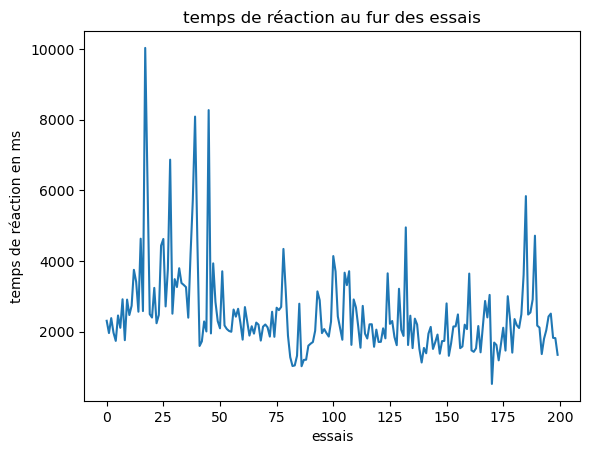

In [9]:
plt.plot(df_filtered["trial_rt"])
plt.title("temps de réaction au fur des essais")
plt.xlabel("essais")
plt.ylabel("temps de réaction en ms")
plt.show()

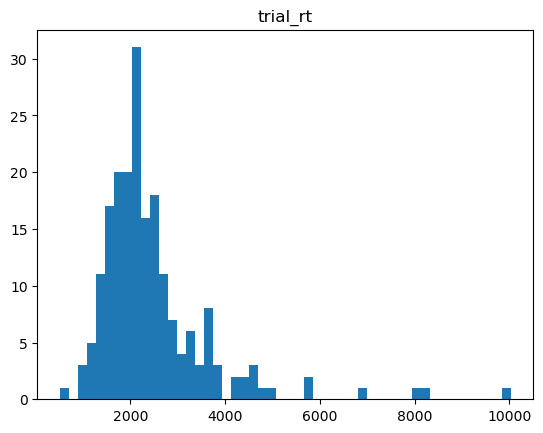

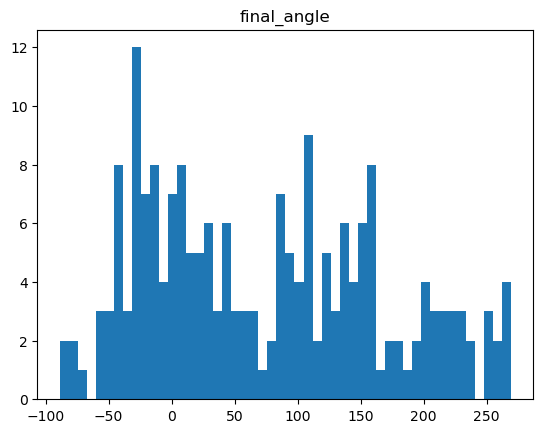

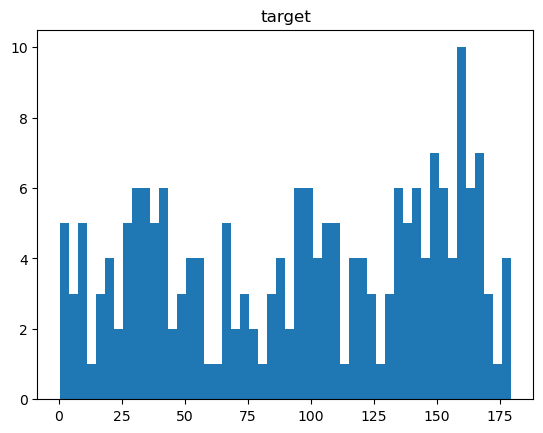

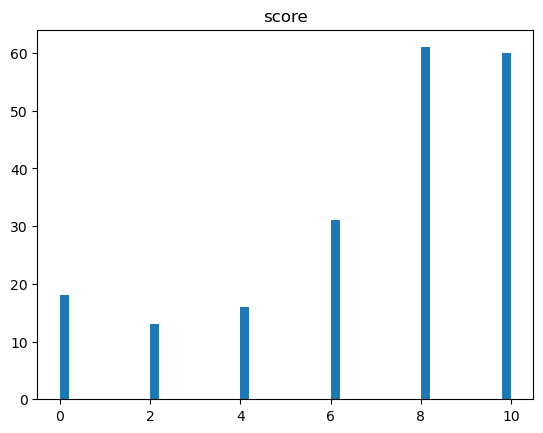

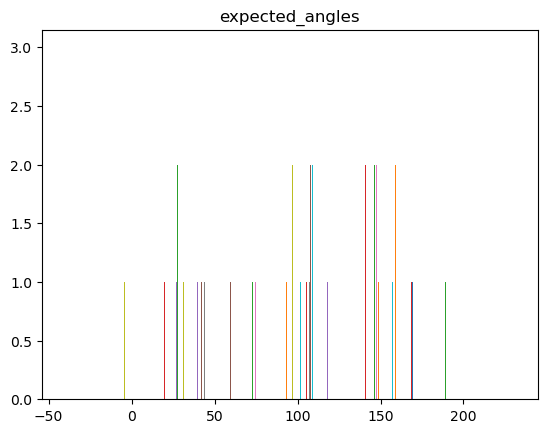

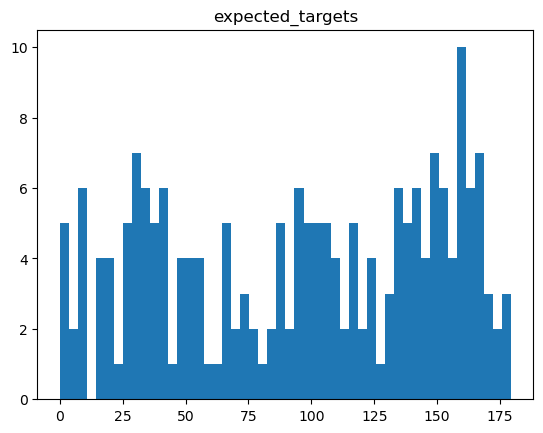

In [10]:
for column in df_filtered.columns:
    if column not in ["presented_angles", "stimulus_rotations"]:
        plt.figure()
        plt.hist(df_filtered[column], bins=50)
        plt.title(column)
        plt.show()

### data sur tous les participants

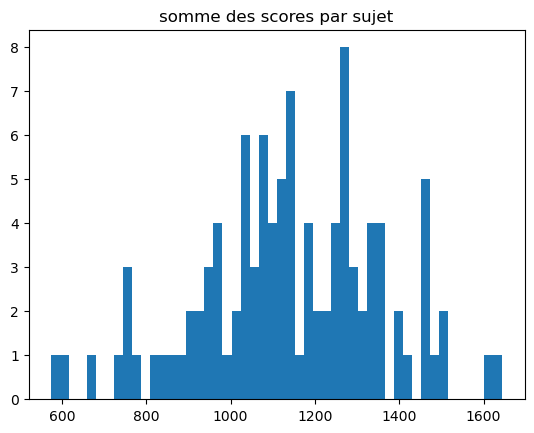

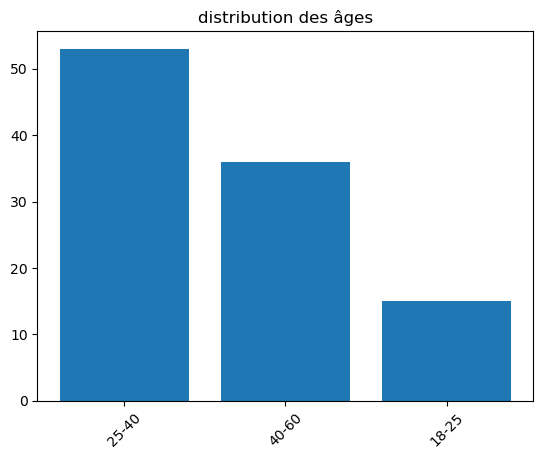

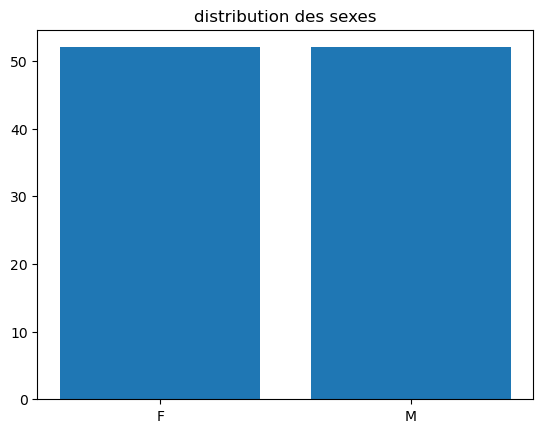

In [11]:
filepaths = glob.glob("données/*.csv")
dfs = [pd.read_csv(f, skiprows=1, index_col=3) for f in filepaths]

def data_sujets (dfs) : 
    score_sum = []
    age_tot = []
    sexe_tot = []
    for df in dfs :    
        survey = df[df["trial_type"] == "survey-dropdown"]
        if len(survey) == 0:
            age, sexe = None, None
        else:
            resp = json.loads(survey.iloc[0]["responses"])
            age = resp.get("0")
            sexe = resp.get("1")        
        age_tot.append(age)
        sexe_tot.append(sexe)
        
        df_filtered = df[df["stimulus_rotations"].notna()].copy()
        df_filtered = df_filtered.dropna(subset=["final_angle"]).copy()
        
        df_filtered['score'] = pd.to_numeric(df_filtered["score"], errors="coerce")
        score_sum.append(df_filtered["score"].sum(skipna=True))
        
    return score_sum, age_tot, sexe_tot

scores, ages, sexes = data_sujets(dfs)

plt.hist(scores, bins=50)
plt.title("somme des scores par sujet")
plt.show()

age_counts = pd.Series(ages).value_counts(dropna=False)
plt.bar(age_counts.index.astype(str), age_counts.values)
plt.xticks(rotation=45)
plt.title("distribution des âges")
plt.show()

sex_counts = pd.Series(sexes).value_counts(dropna=False)
plt.bar(sex_counts.index.astype(str), sex_counts.values)
plt.title("distribution des sexes")
plt.show()

In [12]:
print("il y a",sexes.count('F'), "femmes"), print("il y a",sexes.count('M'), 'hommes'), print("il y a",ages.count('18-25'), "personnes qui ont entre 18 et 25 ans"),
print("il y a",ages.count('25-40'), 'personnes qui ont entre 25 et 40 ans'), print("il y a",ages.count('40-60'), 'personnes qui ont entre 40 et 60 ans')

il y a 52 femmes
il y a 52 hommes
il y a 15 personnes qui ont entre 18 et 25 ans
il y a 53 personnes qui ont entre 25 et 40 ans
il y a 36 personnes qui ont entre 40 et 60 ans


(None, None)

### Disposition des angles sur un cercle

ici je dois changer en mettant le cercle de -90° à 90°
ca c'est bizarre


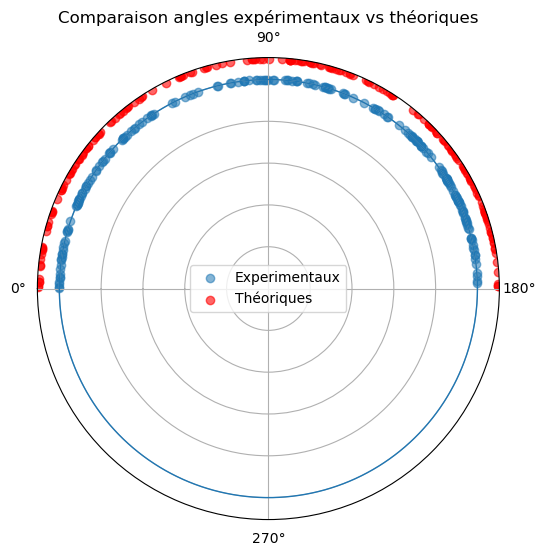

In [13]:
fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

ax.set_theta_zero_location("W")   # 0° à gauche (comme ton choix)
ax.set_theta_direction(-1)        # sens horaire

# ---- CERCLE TRIGONOMÉTRIQUE ----
theta = np.linspace(0, 2*np.pi, 400)
ax.plot(theta, np.ones_like(theta), linewidth=1)  # cercle unité

# labels angulaires
ax.set_thetagrids(
    angles=[0, 90, 180, 270],
    labels=["0°", "90°", "180°", "270°"]
)

# ---- TES DONNÉES ----
theta_presented = df_radian['final_angle'].values
theta_targets = df_radian['target'].values

ax.scatter(theta_presented, np.ones_like(theta_presented),
           alpha=0.55, label="Experimentaux")

ax.scatter(theta_targets, np.ones_like(theta_targets)*1.1,
           color='red', alpha=0.6, label="Théoriques")

ax.set_yticklabels([])   # enlève les labels du rayon
ax.set_title("Comparaison angles expérimentaux vs théoriques")
ax.legend()

plt.show()

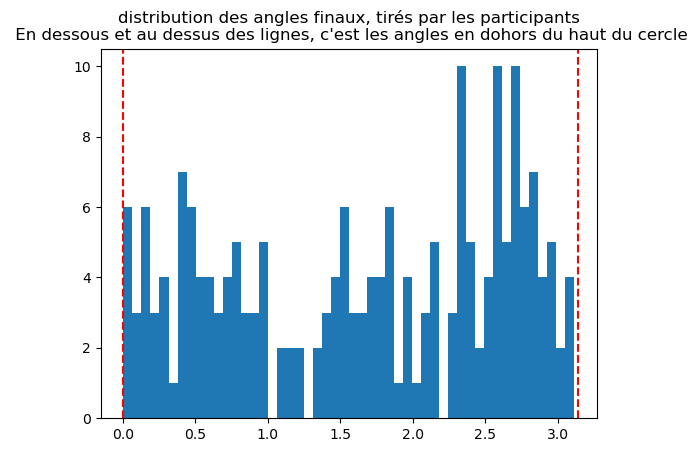

In [14]:
plt.hist(df_radian["final_angle"], bins=50)
plt.axvline(0, color='red', linestyle='--')
plt.axvline(np.pi, color='red', linestyle='--')
plt.title("distribution des angles finaux, tirés par les participants\n En dessous et au dessus des lignes, c'est les angles en dohors du haut du cercle")
plt.show()

## Implication des rotations dans la détermination des angles

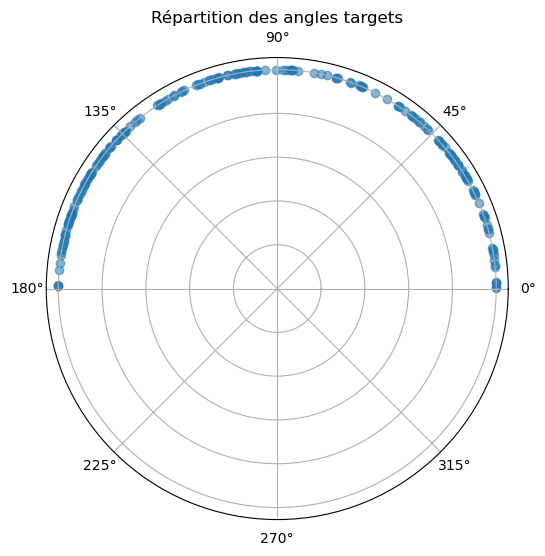

In [15]:
fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

ax.scatter(df_radian['expected_targets'], np.ones_like(df_radian['expected_targets']),
           alpha=0.55)

ax.set_yticklabels([])
ax.set_title("Répartition des angles targets")
plt.show()

est ce que les participants ont bien répondu ? : performances 

In [16]:
df_radian["error_to_target"] = circular_error_180(df_radian["final_angle"], df_radian["expected_targets"])

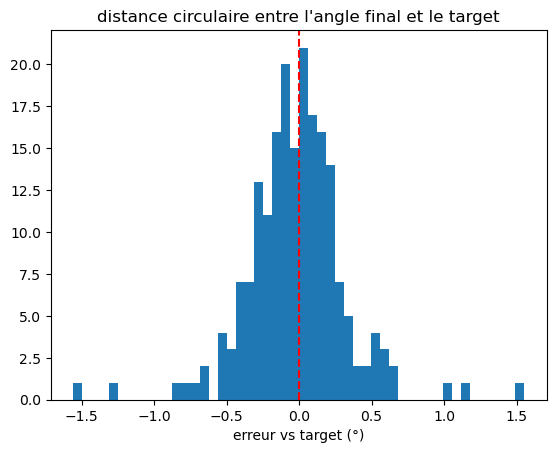

In [17]:
plt.hist(df_radian["error_to_target"], bins=50)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("erreur vs target (°)")
plt.title("distance circulaire entre l'angle final et le target")
plt.show()

est ce que ce participant se comporte en ignorant la rotation ?

In [18]:
# 1. regarder la moyenne circulaire des angles vues par les participants sans les rotations
mean_presented_angles = df_radian['presented_angles'].apply(np.mean)

In [19]:
df_radian['rotation_error'] = circular_error_180(
    (df_radian['final_angle']),
    mean_presented_angles
)

Erreur = ce que le participant a répondu
− ce qu’il aurait dû répondre s’il appliquait parfaitement la rotation

Gros pic autour de 0°
-> Les gens font bien la rotation

Pics autour de ±45°
-> Les gens répondent comme s’il n’y avait pas de rotation

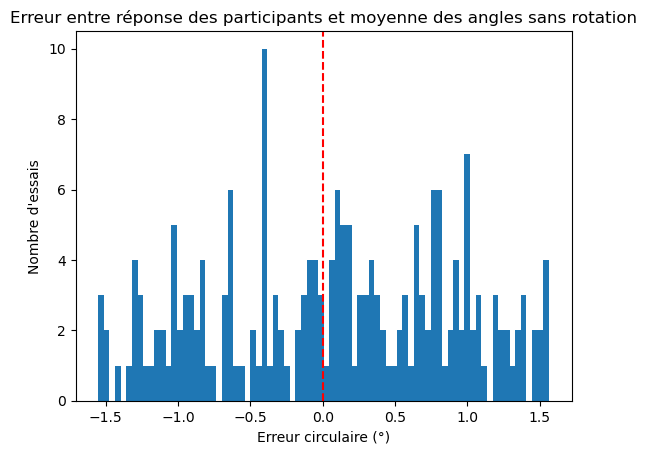

In [20]:
plt.hist(df_radian['rotation_error'], bins=80)
plt.axvline(0, color='red', linestyle='--')
plt.xlabel("Erreur circulaire (°)")
plt.ylabel("Nombre d'essais")
plt.title("Erreur entre réponse des participants et moyenne des angles sans rotation")
plt.show()
